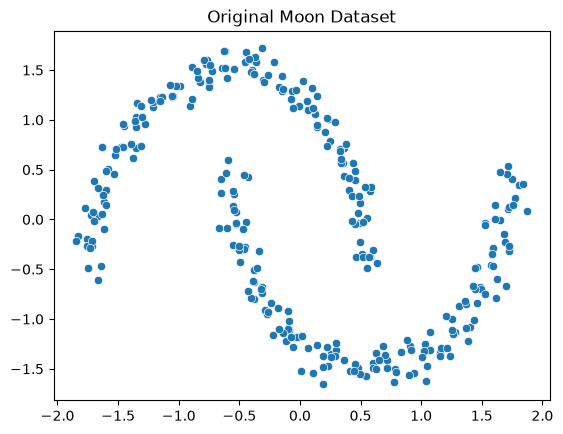

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

X, y = make_moons(
    n_samples=300,
    noise=0.05,
    random_state=42
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1]
)

plt.title("Original Moon Dataset")
plt.show()

# Apply K-Means Clustering

In [2]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

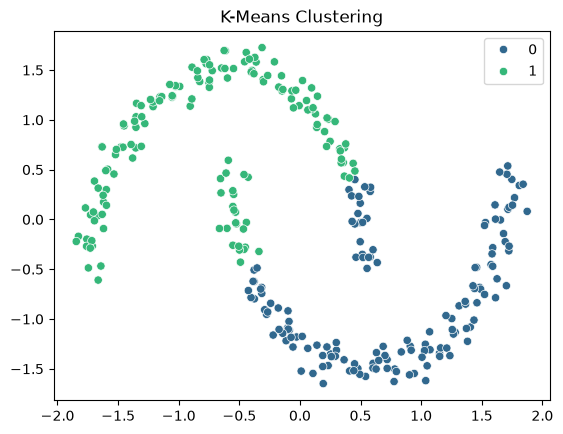

In [3]:
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=kmeans_labels,
    palette="viridis"
)

plt.title("K-Means Clustering")
plt.show()

# Apply DBSCAN Clustering

In [4]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.25,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

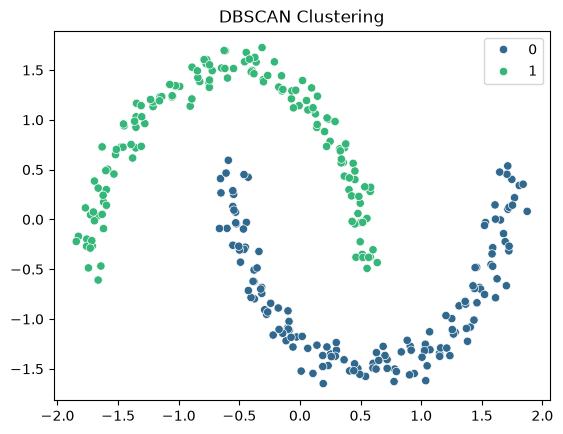

In [5]:
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=dbscan_labels,
    palette="viridis"
)

plt.title("DBSCAN Clustering")
plt.show()

# Apply Hierarchical Clustering

## 1. Agglomerative Clustering

In [6]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(
    n_clusters=2,
    linkage="single"
)

agg_labels = agg.fit_predict(X_scaled)

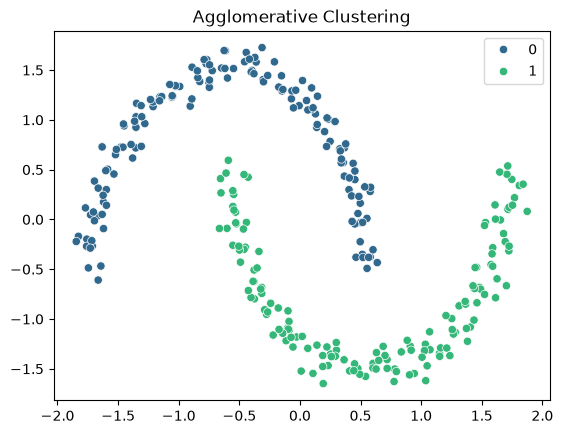

In [7]:
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=agg_labels,
    palette="viridis"
)

plt.title("Agglomerative Clustering")
plt.show()

## 2. Apply Divisive Clustering

In [8]:
from sklearn.cluster import BisectingKMeans

divisive = BisectingKMeans(
    n_clusters=2,
    random_state=42
)

divisive_labels = divisive.fit_predict(X_scaled)

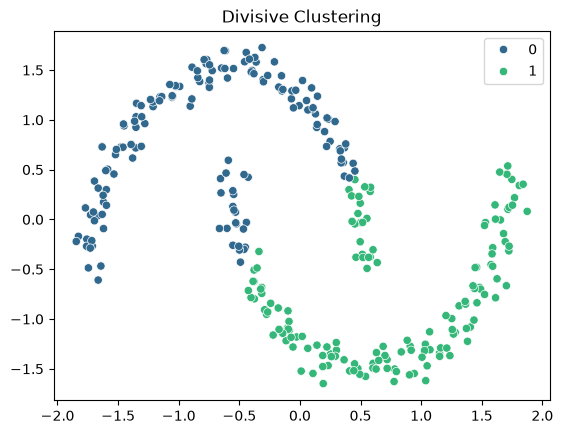

In [9]:
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=divisive_labels,
    palette="viridis"
)

plt.title("Divisive Clustering")
plt.show()

# Compare all four algorithms together

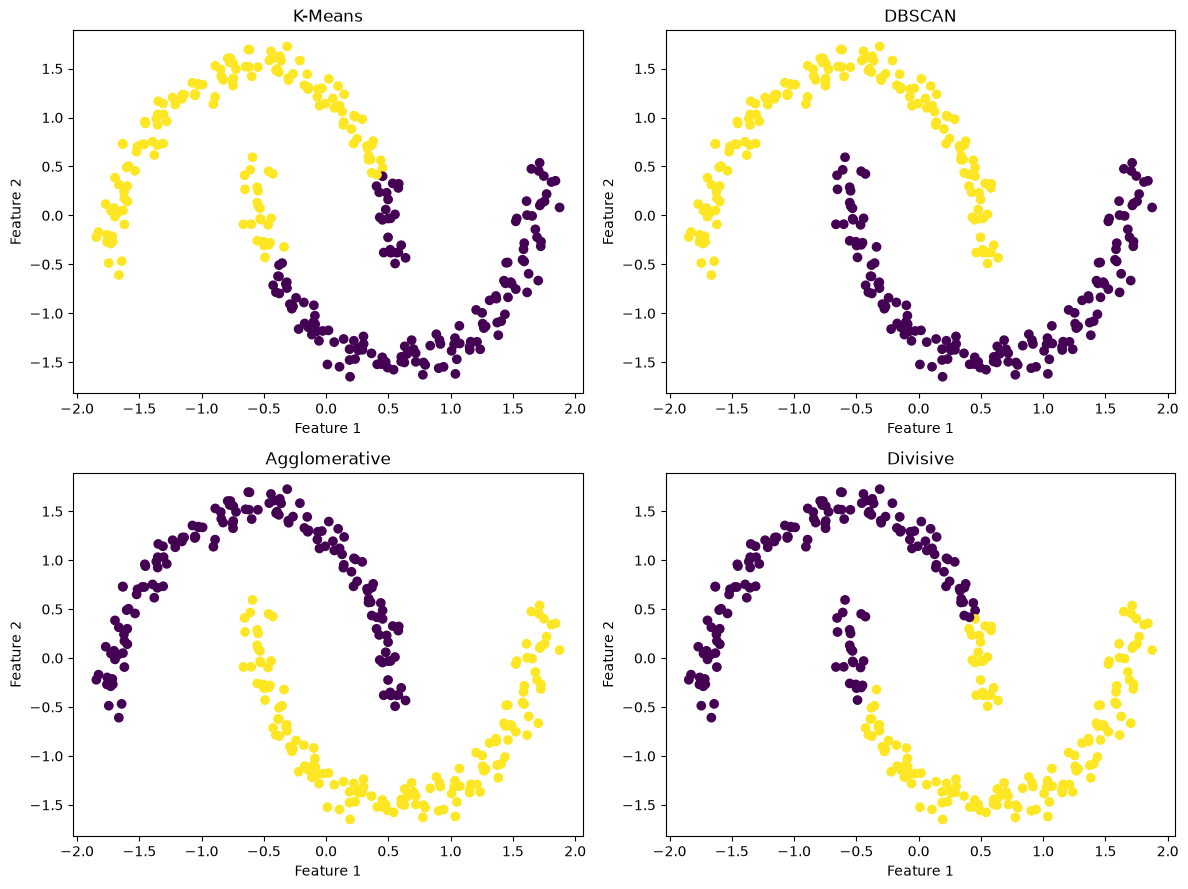

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

results = [
    ("K-Means", kmeans_labels),
    ("DBSCAN", dbscan_labels),
    ("Agglomerative", agg_labels),
    ("Divisive", divisive_labels)
]

for ax, (name, labels) in zip(axes.flat, results):

    ax.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=labels,
        cmap="viridis"
    )

    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import adjusted_rand_score

print("KMeans:", adjusted_rand_score(y, kmeans_labels))

print("DBSCAN:", adjusted_rand_score(y, dbscan_labels))

print("Agglomerative:", adjusted_rand_score(y, agg_labels))

print("Divisive:", adjusted_rand_score(y, divisive_labels))

KMeans: 0.46973773754843584
DBSCAN: 1.0
Agglomerative: 1.0
Divisive: 0.47896853094705444
